# Задание 13. Калибровка модуля оценки риска

**Проект:** SMS Guard · **Автор:** Омаров М.Е., SIS-2304

Формула (раздел 2.5 / задание 13 ТЗ), реализация — `ml/risk.py`, параметры — `risk_config.yaml`:

$$\text{RiskScore} = 100 \cdot \frac{w_1 P_{sms} + w_2 P_{url,max} + w_3 S_{se}}{w_1 + w_2 [\text{URL есть}] + w_3},\quad S_{se} = \min(k/3, 1)$$

После формулы — правила усиления: `CODE_REQUEST` → не ниже 70; $P_{sms} \ge 0{,}8$ и $P_{url,max} \ge t_2$ → не ниже 85;
ссылка с IP-адресом или Punycode → не ниже 60.

**Данные калибровки:** validation SMS (UCI en + синтетика ru/kk, задание 6) и собственный набор 150 SMS (задание 3).
$P_{sms}$ считается моделью итоговой конфигурации задания 8, **обученной только на train** (итоговая модель дообучена
на train + validation, и на validation её вероятности были бы завышены). URL-модель (задание 11) обучена только на train URL.
Test SMS используется один раз — для проверки уже выбранного варианта.

**Цель ТЗ:** Recall мошеннических SMS по уровню «средний и выше» ≥ 0,95; доля безопасных SMS на уровне «высокий» < 3%.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
warnings.filterwarnings("ignore")
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)

from ml import calibrate_risk as cr  # noqa: E402
from ml import train_sms as ts  # noqa: E402
from ml.predictor import Predictor  # noqa: E402
from ml.risk import compute_risk, load_config  # noqa: E402

FIG_DIR = PROJECT_ROOT / "docs" / "figures"
data = ts.load_data()
sms_model = cr.train_only_sms_model(data)
predictor = Predictor()
t1, t2 = predictor.url_thresholds
print(f"Пороги URL-модели: t1 = {t1}, t2 = {t2}")

val = cr.collect_components(data.val, sms_model, predictor)
custom = cr.collect_components(data.custom, sms_model, predictor)
calib = pd.concat([val.assign(set="validation"), custom.assign(set="собственный")], ignore_index=True)
calib.groupby(["set", "lang"]).agg(SMS=("label", "size"), мошеннических=("label", "sum"),
                                   с_URL=("n_urls", lambda s: int((s > 0).sum())),
                                   с_группами_СИ=("k", lambda s: int((s > 0).sum())))

Пороги URL-модели: t1 = 0.2003, t2 = 0.6638


SMS  мошеннических  с_URL  с_группами_СИ
set         lang                                          
validation  en    770             93     16             89
            kk    182             97     88            132
            ru    185             97     61            102
собственный kk     50             25     16             32
            ru    100             50     34             56

## 1. Таблица калибровки

Перебор: 7 вариантов весов × 5 вариантов границ уровней = 35 вариантов. Для каждого — Recall мошеннических по уровню
«средний+» и по уровню «высокий», доля безопасных на уровне «высокий» (ложные высокие) и «средний+».

In [2]:
table = cr.run_grid(calib, t2)
table.rename(columns={"recall_medium_plus": "Recall (средний+)", "recall_high": "Recall (высокий)",
                      "safe_high_share": "доля ложных высоких", "safe_medium_plus_share": "доля безопасных средний+",
                      "meets_goal": "цель ТЗ"})

,w_sms,w_url,w_se,low_max,medium_max,Recall (средний+),Recall (высокий),доля ложных высоких,доля безопасных средний+,цель ТЗ
0,0.5,0.3,0.2,34,69,0.9779,0.8867,0.0,0.0022,True
1,0.5,0.3,0.2,29,69,0.9779,0.8867,0.0,0.0022,True
2,0.5,0.3,0.2,24,69,0.9779,0.8867,0.0,0.0022,True
3,0.5,0.3,0.2,34,64,0.9779,0.9171,0.0,0.0022,True
4,0.5,0.3,0.2,29,59,0.9779,0.9365,0.0,0.0022,True
5,0.6,0.2,0.2,34,69,0.9779,0.9227,0.0,0.0022,True
6,0.6,0.2,0.2,29,69,0.9779,0.9227,0.0,0.0022,True
7,0.6,0.2,0.2,24,69,0.9779,0.9227,0.0,0.0032,True
8,0.6,0.2,0.2,34,64,0.9779,0.9475,0.0,0.0022,True
9,0.6,0.2,0.2,29,59,0.9779,0.9586,0.0,0.0022,True


Все 35 вариантов достигают цели: на validation SMS-модель уверенно разделяет классы, а словарь и URL-модель добавляют
сигнал. Различия — в том, какая доля мошенничества попадает в «высокий» уровень.

**Правило выбора** (зафиксировано до проверки на test, `ml/calibrate_risk.choose`):
1. вариант достигает цели ТЗ;
2. границы уровней ТЗ 34/69 сохраняются, если с ними цель достижима — их видит пользователь в интерфейсе;
3. вес словаря $w_3 \ge 0{,}2$ — словарь не зависит от SMS-модели, а для ru/kk модель проверена только на искусственных
   сообщениях; без этого ограничения перебор выбирает максимальный вес $P_{sms}$;
4. среди оставшихся — минимальная доля безопасных на уровне «средний+», затем максимальный Recall уровня «высокий».

In [3]:
main = table[(table["low_max"] == 34) & (table["medium_max"] == 69)].copy()
main["веса (w1, w2, w3)"] = main.apply(lambda r: f"{r.w_sms} / {r.w_url} / {r.w_se}", axis=1)
best = cr.choose(table)
print("Выбран вариант:", best[["w_sms", "w_url", "w_se", "low_max", "medium_max"]].to_dict())
main[["веса (w1, w2, w3)", "recall_medium_plus", "recall_high", "safe_high_share", "safe_medium_plus_share",
      "meets_goal"]].rename(columns={"recall_medium_plus": "Recall (средний+)", "recall_high": "Recall (высокий)",
                                     "safe_high_share": "доля ложных высоких",
                                     "safe_medium_plus_share": "доля безопасных средний+"}).reset_index(drop=True)

Выбран вариант: {'w_sms': 0.6, 'w_url': 0.2, 'w_se': 0.2, 'low_max': 34, 'medium_max': 69}


,"веса (w1, w2, w3)",Recall (средний+),Recall (высокий),доля ложных высоких,доля безопасных средний+,meets_goal
0,0.5 / 0.3 / 0.2,0.9779,0.8867,0.0,0.0022,True
1,0.6 / 0.2 / 0.2,0.9779,0.9227,0.0,0.0022,True
2,0.4 / 0.3 / 0.3,0.9724,0.7901,0.0,0.0022,True
3,0.5 / 0.2 / 0.3,0.9696,0.8398,0.0,0.0022,True
4,0.6 / 0.3 / 0.1,0.9779,0.9227,0.0,0.0022,True
5,0.4 / 0.4 / 0.2,0.9724,0.8011,0.0,0.0022,True
6,0.7 / 0.2 / 0.1,0.9779,0.9558,0.0,0.0022,True


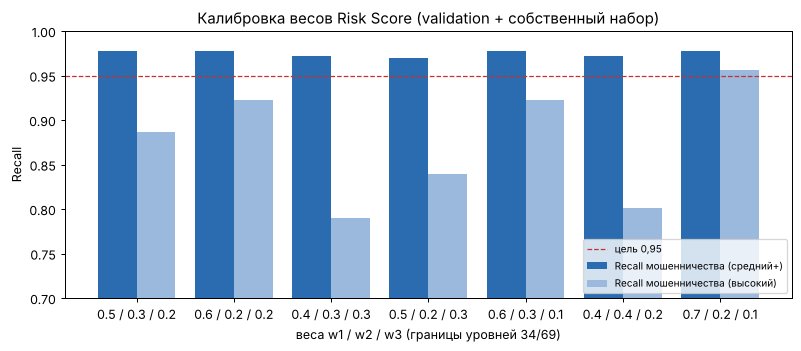

In [4]:
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(main))
ax.bar(x - 0.2, main["recall_medium_plus"], 0.4, label="Recall мошенничества (средний+)", color="#2b6cb0")
ax.bar(x + 0.2, main["recall_high"], 0.4, label="Recall мошенничества (высокий)", color="#9bb8dd")
ax.axhline(0.95, color="#c53030", ls="--", lw=1, label="цель 0,95")
ax.set_xticks(x, main["веса (w1, w2, w3)"])
ax.set_ylim(0.7, 1.0)
ax.set_xlabel("веса w1 / w2 / w3 (границы уровней 34/69)")
ax.set_ylabel("Recall")
ax.set_title("Калибровка весов Risk Score (validation + собственный набор)")
ax.legend(loc="lower right", fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "13_calibration.png", dpi=120)
plt.show()

## 2. Запись выбранного варианта в `risk_config.yaml`

In [5]:
cr.save_choice(best)
cfg = load_config()
print("weights:", cfg["weights"], "levels:", cfg["levels"])

weights: {'w_sms': 0.6, 'w_url': 0.2, 'w_se': 0.2} levels: {'low_max': 34, 'medium_max': 69}


## 3. Распределение Risk Score (выбранный вариант)

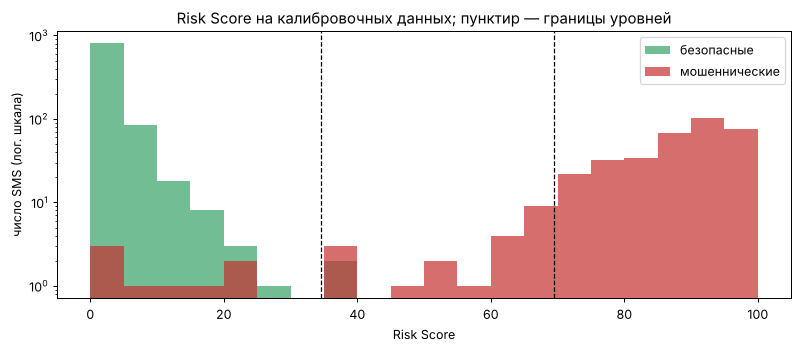

,набор,язык,SMS,recall_medium_plus,recall_high,safe_high_share,safe_medium_plus_share
0,validation,en,770,0.9247,0.7957,0.0,0.003
1,validation,kk,182,1.0000,1.0000,0.0,0.000
2,validation,ru,185,1.0000,0.9897,0.0,0.000
3,собственный,kk,50,1.0000,0.9600,0.0,0.000
4,собственный,ru,100,0.9800,0.8600,0.0,0.000


In [6]:
calib["score"] = cr.scores_for(calib, cfg, t2)
fig, ax = plt.subplots(figsize=(9, 4))
bins = np.arange(0, 105, 5)
ax.hist(calib.loc[calib.label == 0, "score"], bins=bins, alpha=0.7, label="безопасные", color="#38a169")
ax.hist(calib.loc[calib.label == 1, "score"], bins=bins, alpha=0.7, label="мошеннические", color="#c53030")
for b in (34.5, 69.5):
    ax.axvline(b, color="black", ls="--", lw=1)
ax.set_yscale("log")
ax.set_xlabel("Risk Score")
ax.set_ylabel("число SMS (лог. шкала)")
ax.set_title("Risk Score на калибровочных данных; пунктир — границы уровней")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "13_score_distribution.png", dpi=120)
plt.show()

per_set = []
for (name, lang), g in calib.groupby(["set", "lang"]):
    m = cr.evaluate(g, g["score"].to_numpy(), cfg)
    per_set.append({"набор": name, "язык": lang, "SMS": len(g), **m})
pd.DataFrame(per_set)

Пропущенные мошеннические SMS (уровень «низкий») и безопасные SMS с уровнем «средний+»:

In [7]:
texts = pd.concat([data.val["text_raw"], data.custom["text_raw"]], ignore_index=True)
calib["text"] = texts
cols = ["set", "lang", "text", "p_sms", "p_url_max", "k", "score"]
print("Мошеннические с низким уровнем:")
print(calib[(calib.label == 1) & (calib.score <= 34)][cols].to_string(max_colwidth=90))
print("\nБезопасные со средним или высоким уровнем:")
print(calib[(calib.label == 0) & (calib.score >= 35)][cols].to_string(max_colwidth=90))

Мошеннические с низким уровнем:
              set lang                                                                                       text     p_sms  p_url_max  k  score
202    validation   en                    For sale - arsenal dartboard. Good condition but no doubles or trebles!  0.001861        NaN  0      0
212    validation   en  SMS. ac JSco: Energy is high, but u may not know where 2channel it. 2day ur leadership...  0.079740        NaN  0      6
382    validation   en  Burger King - Wanna play footy at a top stadium? Get 2 Burger King before 1st Sept and...  0.095259        NaN  1     15
383    validation   en  How come it takes so little time for a child who is afraid of the dark to become a tee...  0.000588        NaN  0      0
581    validation   en                 accordingly. I repeat, just text the word ok on your mobile phone and send  0.312839        NaN  0     23
675    validation   en  Hi this is Amy, we will be sending you a free phone number in a couple of 

## 4. Проверка на test (однократно, после выбора)

Для test берётся итоговая SMS-модель задания 8 (`sms_model.joblib`, обучена на train + validation) — так работает
приложение.

In [8]:
test = cr.collect_components(data.test, predictor.sms_model, predictor)
test["score"] = cr.scores_for(test, cfg, t2)
rows = [{"язык": "все", "SMS": len(test), **cr.evaluate(test, test["score"].to_numpy(), cfg)}]
for lang, g in test.groupby("lang"):
    rows.append({"язык": lang, "SMS": len(g), **cr.evaluate(g, g["score"].to_numpy(), cfg)})
test_table = pd.DataFrame(rows)
test_table

,язык,SMS,recall_medium_plus,recall_high,safe_high_share,safe_medium_plus_share
0,все,1146,0.9723,0.9204,0.0082,0.0373
1,en,771,0.9140,0.7742,0.0000,0.0044
2,kk,188,1.0000,0.9796,0.0778,0.1444
3,ru,187,1.0000,1.0000,0.0000,0.1798


## 5. Демонстрационные сообщения (раздел 8.3)

In [9]:
import os  # noqa: E402

import django  # noqa: E402

os.environ.setdefault("DJANGO_SETTINGS_MODULE", "config.settings")
os.environ.setdefault("SECRET_KEY", "notebook-only-not-secret")  # ноутбук не запускает сервер
django.setup()
from apps.analysis.services import analyze_sms, analyze_url  # noqa: E402

demo = [
    "Привет! Встречаемся завтра в 18:00 у входа в библиотеку.",
    "Your order #4821 has been shipped and will arrive on Monday.",
    "Сәлем! Ертең сағат 10:00-де кездесеміз бе?",
    "Ваш код подтверждения: 4821. Никому не сообщайте этот код.",
    "Ваша карта заблокирована! Срочно подтвердите данные по ссылке: http://secure-bank-verify.example/login",
    "URGENT: Your account will be suspended in 24 hours. Verify now at http://192.0.2.15/account-update",
    "Мама, у меня проблемы, срочно переведи 50 000 на этот номер, потом всё объясню. Никому не говори.",
    "Congratulations! You won a $1000 gift card. Claim your prize: bit.ly/prize-claim-test",
    "Сотрудник службы безопасности банка: назовите код из SMS для отмены подозрительной операции.",
    "Картаңыз бұғатталды. Жедел түрде мына сілтеме арқылы растаңыз: http://bank-kz-verify.test",
    "Ваша посылка ожидает оплаты таможенного сбора 350 T: http://post-delivery-pay.example",
]
rows = []
for i, text in enumerate(demo, 1):
    r = analyze_sms(text, predictor)
    rows.append({"№": i, "язык": r.language, "P_sms": round(r.p_sms, 3),
                 "P_url,max": None if r.p_url_max is None else round(r.p_url_max, 3), "группы": ", ".join(r.features),
                 "база": r.base_score, "усиление": ", ".join(r.applied_overrides), "Risk Score": r.risk_score,
                 "уровень": r.risk_level, "категория": r.category})
for i, url in enumerate(["https://www.example.com/about", "http://xn--exmple-cua.test/secure/login?verify=1"], 12):
    r = analyze_url(url, predictor)
    rows.append({"№": i, "язык": "URL", "P_sms": None, "P_url,max": round(r.p_url_max, 3), "группы": "",
                 "база": r.base_score, "усиление": ", ".join(r.applied_overrides), "Risk Score": r.risk_score,
                 "уровень": r.risk_level, "категория": r.category})
demo_table = pd.DataFrame(rows)
demo_table

,№,язык,P_sms,"P_url,max",группы,база,усиление,Risk Score,уровень,категория
0,1,ru,0.001,NaN,,0.04,,0,LOW,SAFE
1,2,en,0.014,NaN,,1.05,,1,LOW,SAFE
2,3,kk,0.000,NaN,,0.03,,0,LOW,SAFE
3,4,ru,0.002,NaN,,0.17,,0,LOW,SAFE
4,5,ru,1.000,0.999,"URGENCY, BANK_CARD, ACCOUNT_BLOCK, LINK_REQUEST",99.97,,100,HIGH,FRAUDULENT
5,6,en,1.000,1.000,"URGENCY, BANK_CARD, ACCOUNT_BLOCK, LINK_REQUEST",99.98,,100,HIGH,FRAUDULENT
6,7,ru,0.642,NaN,"URGENCY, MONEY_TRANSFER",64.84,,65,MEDIUM,SUSPICIOUS
7,8,en,1.000,1.000,"BANK_CARD, PRIZE, LINK_REQUEST",100.00,,100,HIGH,FRAUDULENT
8,9,ru,0.993,NaN,"BANK_CARD, ACCOUNT_BLOCK, CODE_REQUEST",99.50,,100,HIGH,FRAUDULENT
9,10,kk,1.000,0.988,"URGENCY, BANK_CARD, ACCOUNT_BLOCK, LINK_REQUEST",99.75,,100,HIGH,FRAUDULENT


In [10]:
r = analyze_sms(demo[4], predictor)
print("Причины:")
for line in r.explanation:
    print(" -", line)
print("Рекомендация:", r.recommendation)
print(r.disclaimer)

Причины:
 - Текст похож на мошеннические сообщения (вероятность по SMS-модели 1.00)
 - Ссылка в сообщении похожа на опасную (вероятность по URL-модели 1.00)
 - secure-bank-verify.example: подозрительные слова в адресе: bank, login, secure, verify
 - secure-bank-verify.example: много дефисов в домене
 - secure-bank-verify.example: соединение без шифрования (HTTP, а не HTTPS)
 - Требование срочного действия: «срочн»
Рекомендация: Не переходите по ссылке, не сообщайте коды и данные карты, не переводите деньги. Свяжитесь с банком или отправителем по номеру с обратной стороны карты или из официального приложения.
Оценка носит вероятностный характер и не гарантирует безопасность


## 6. Выводы

1. **Выбран вариант w1 = 0,6; w2 = 0,2; w3 = 0,2, уровни 0–34 / 35–69 / 70–100** (границы ТЗ сохранены). На калибровочных
   данных (validation + собственный набор, 1287 SMS): Recall мошенничества по уровню «средний+» 0,978, по уровню «высокий»
   0,923, доля безопасных на уровне «высокий» 0%. Цель ТЗ достигнута; значения записаны в `risk_config.yaml`.
2. Цель достигают все 35 вариантов, поэтому выбор определяло правило из раздела 1 (границы ТЗ, вес словаря ≥ 0,2, затем
   Recall уровня «высокий»). Без ограничения на вес словаря был бы выбран вариант 0,7 / 0,2 / 0,1.
3. По отдельности цель выполнена не для всех языков: английская часть validation даёт Recall «средний+» 0,925 — пропущены
   спам-сообщения без «мошеннических» слов (реклама, знакомства). Для ru/kk — 0,98–1,0.
4. **Test (однократно):** Recall «средний+» 0,972, доля безопасных на уровне «высокий» 0,8% — цель выполнена для набора в целом.
   Но у искусственных казахских безопасных SMS доля «высоких» 7,8%, у русских доля «средний+» 18% (en — 0,4%). Это те же
   ложные срабатывания SMS-модели на шаблонах доставки и акций, что и в задании 8: калибровка весов их не устраняет.
5. Правила усиления срабатывают на демонстрационных сообщениях: № 9 (код из SMS) — HIGH. Сообщение № 7 («Мама… переведи…
   никому не говори») получило MEDIUM (65): в словаре нет группы секретности, а SMS-модель даёт 0,64. Улучшение — группа
   `SECRECY` и обучающие примеры этого типа.